In [3]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
# 2. Load dataset
df = pd.read_csv('AirQuality.csv', sep=';', decimal=',')
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [8]:
# 3. Preprocess data
df.dropna(axis=1, how='all', inplace=True)
df.dropna(how='all', inplace=True)

df['Time'] = df['Time'].astype(str).str.replace('.', ':', regex=False)

df['DateTime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S'
)

df.set_index('DateTime', inplace=True)
df.drop(['Date', 'Time'], axis=1, inplace=True)

# Replace -200 with missing values
df.replace(-200, np.nan, inplace=True)

In [9]:
# 4. Explore dataset
print("Dataset Information:")
df.info()

print("\nFirst 5 Rows:")
print(df.head())

print("\nDescriptive Statistics:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9357 entries, 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CO(GT)         7674 non-null   float64
 1   PT08.S1(CO)    8991 non-null   float64
 2   NMHC(GT)       914 non-null    float64
 3   C6H6(GT)       8991 non-null   float64
 4   PT08.S2(NMHC)  8991 non-null   float64
 5   NOx(GT)        7718 non-null   float64
 6   PT08.S3(NOx)   8991 non-null   float64
 7   NO2(GT)        7715 non-null   float64
 8   PT08.S4(NO2)   8991 non-null   float64
 9   PT08.S5(O3)    8991 non-null   float64
 10  T              8991 non-null   float64
 11  RH             8991 non-null   float64
 12  AH             8991 non-null   float64
dtypes: float64(13)
memory usage: 1023.4 KB

First 5 Rows:
                     CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  PT08.S2(NMHC)  \
DateTime                              

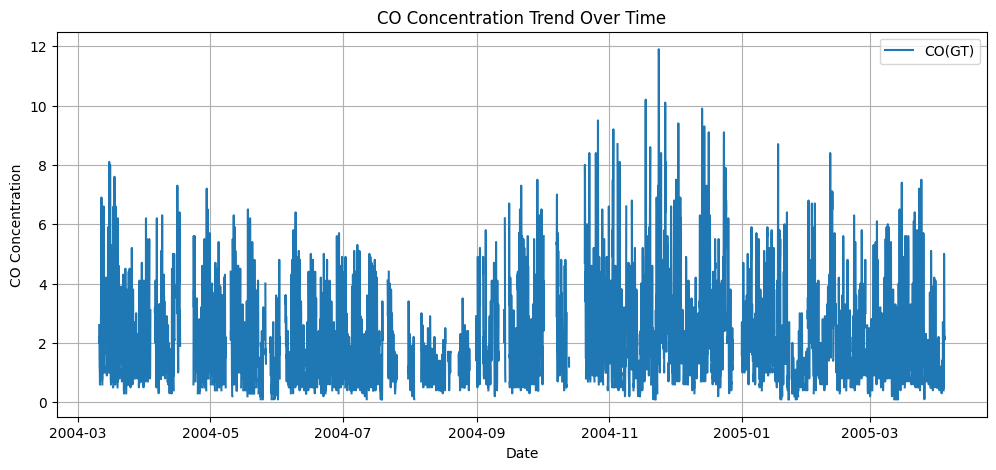

In [10]:
# 5. Line plot: CO concentration over time
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['CO(GT)'], label='CO(GT)')
plt.title('CO Concentration Trend Over Time')
plt.xlabel('Date')
plt.ylabel('CO Concentration')
plt.legend()
plt.grid(True)
plt.show()

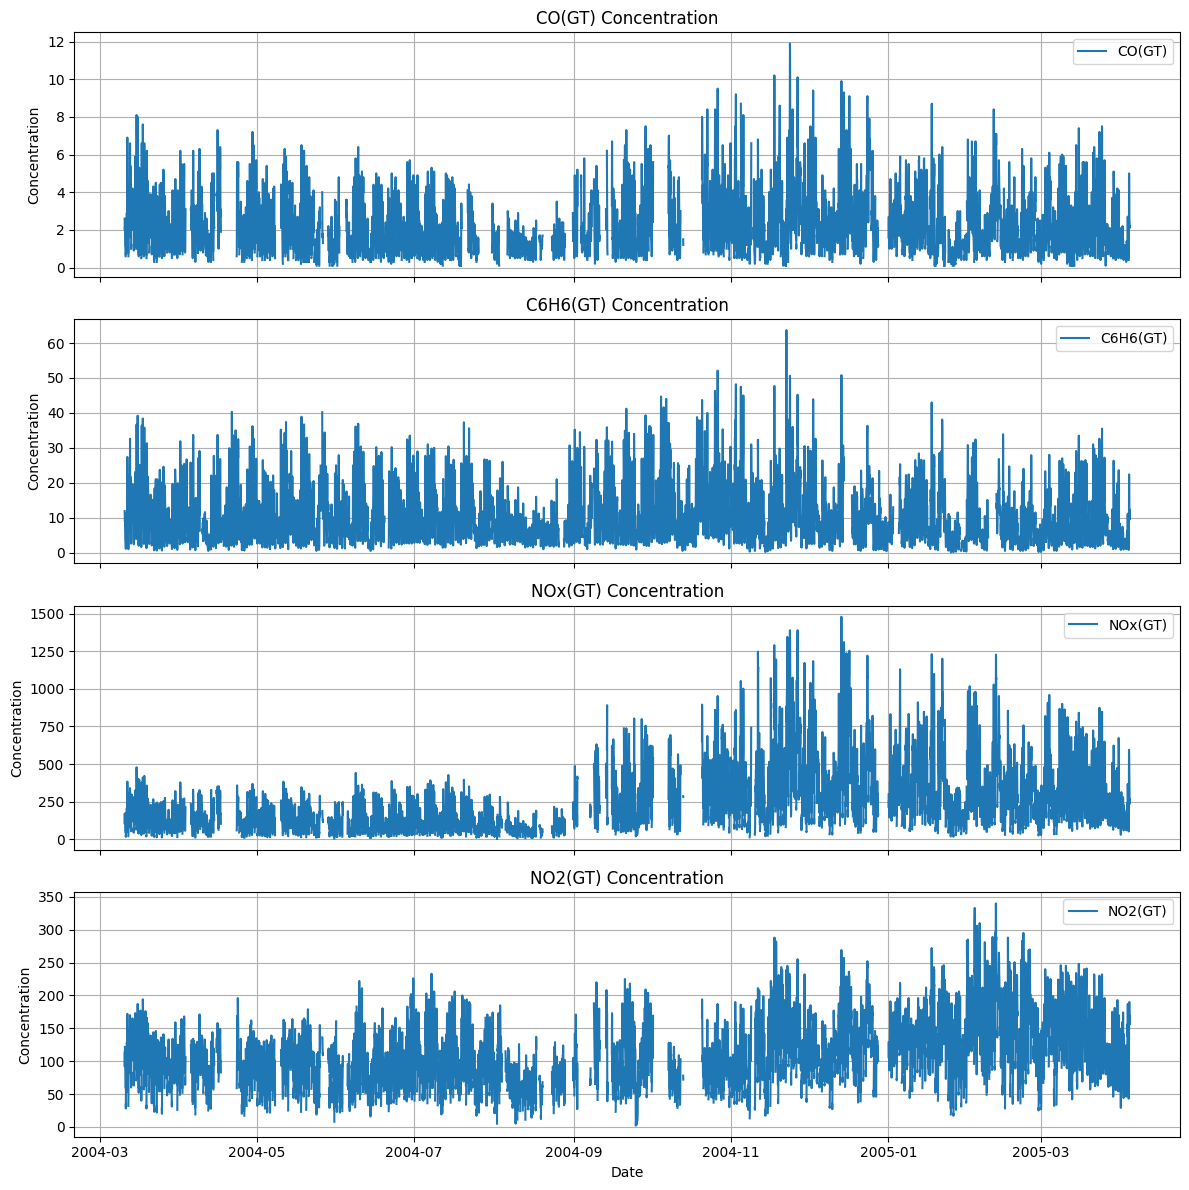

In [11]:
# 6. Subplots for pollutants
pollutants = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

for i, col in enumerate(pollutants):
    axes[i].plot(df.index, df[col], label=col)
    axes[i].set_title(col + ' Concentration')
    axes[i].set_ylabel('Concentration')
    axes[i].legend()
    axes[i].grid(True)

axes[3].set_xlabel('Date')
plt.tight_layout()
plt.show()

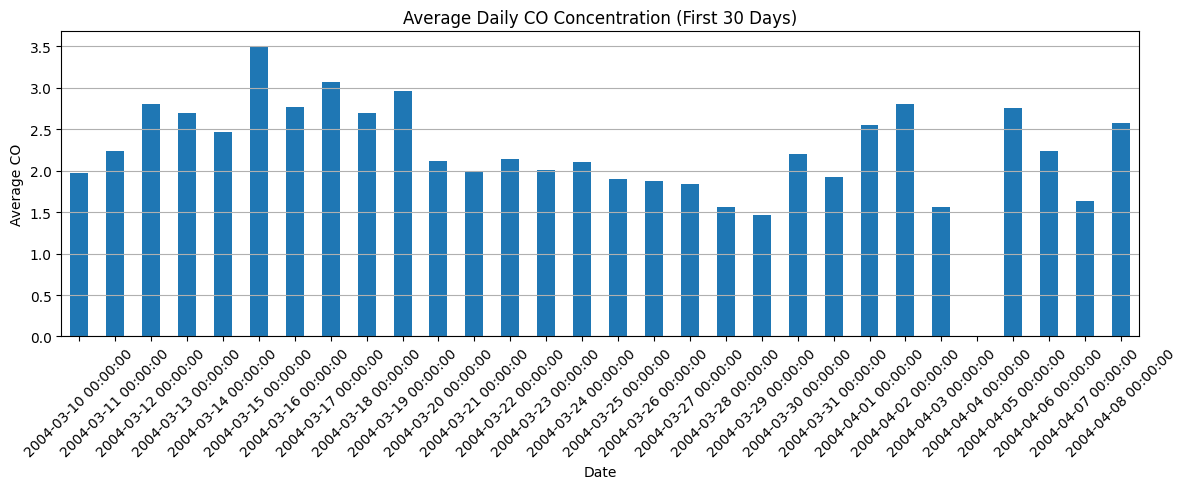

In [12]:
# 7. Bar plot: Average daily CO
daily_co = df['CO(GT)'].resample('D').mean()

plt.figure(figsize=(12, 5))
daily_co.head(30).plot(kind='bar')
plt.title('Average Daily CO Concentration (First 30 Days)')
plt.xlabel('Date')
plt.ylabel('Average CO')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


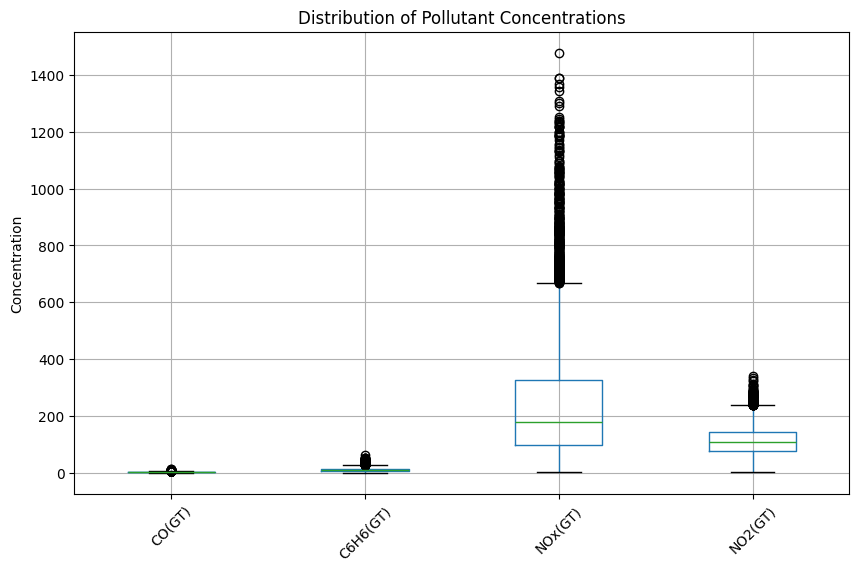

In [13]:
# 8. Box plot
pollutants = df[['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']]

plt.figure(figsize=(10, 6))
pollutants.boxplot()
plt.title('Distribution of Pollutant Concentrations')
plt.ylabel('Concentration')
plt.xticks(rotation=45)
plt.show()

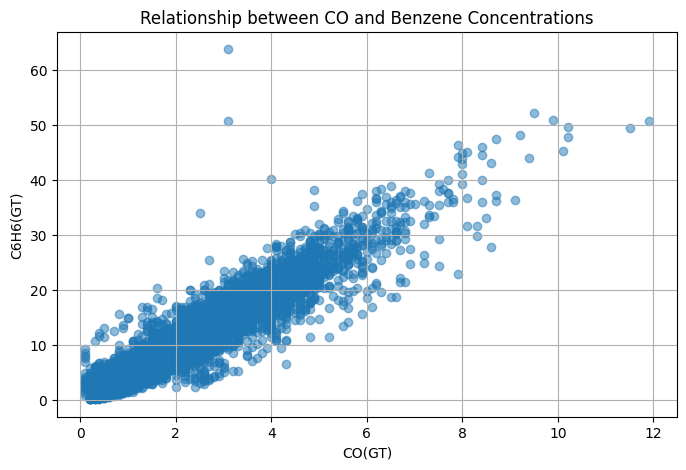

In [14]:
# 9. Scatter plot: CO vs Benzene
plt.figure(figsize=(8, 5))
plt.scatter(df['CO(GT)'], df['C6H6(GT)'], alpha=0.5)
plt.title('Relationship between CO and Benzene Concentrations')
plt.xlabel('CO(GT)')
plt.ylabel('C6H6(GT)')
plt.grid(True)
plt.show()
